In [33]:
# ─── Cell 1: Imports ──────────────────────────────────────────────────────────
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os

In [ ]:
# ─── Cell 2: Load dataset with error handling ─────────────────────────────────

import pandas as pd
import os

CSV_PATH = r"C:\Users\shata\OneDrive\Desktop\4-2\backend\Crop_recommendation.csv"

try:
    print("📂 Files in folder:", os.listdir(r"C:\Users\shata\OneDrive\Desktop\4-2\backend"))
    
    crop = pd.read_csv(CSV_PATH)
    print(f"✅ Loaded dataset: {crop.shape[0]} rows, {crop.shape[1]} columns")
    display(crop.head())

except FileNotFoundError:
    raise FileNotFoundError(
        f"CSV not found at: {CSV_PATH}\n"
        "👉 Check if file name is correct and inside the backend folder."
    )

except pd.errors.EmptyDataError:
    raise ValueError("The CSV file is empty. Please provide a valid dataset.")

except pd.errors.ParserError as e:
    raise ValueError(f"Could not parse CSV: {e}")

📂 Files in folder: ['app.py', 'crop_recommendation.csv', 'desktop.ini', 'train_model.ipynb']
✅ Loaded dataset: 2200 rows, 8 columns


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [35]:
# ─── Cell 3: Data copy & info ──────────────────────────────────────────────────
data = crop.copy()
print("Dataset info:")
data.info()

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [36]:
# ─── Cell 4: Null value check ──────────────────────────────────────────────────
null_counts = data.isnull().sum()
if null_counts.any():
    print("⚠️  Null values detected:")
    print(null_counts[null_counts > 0])
else:
    print("✅ No null values found.")

✅ No null values found.


In [37]:
# ─── Cell 5: Unique values ────────────────────────────────────────────────────
for col in data.columns:
    print(f"\nColumn: {col.upper()}")
    print(f"Unique values: {data[col].nunique()}")
    if data[col].dtype == 'object':
        print(f"Values: {pd.unique(data[col])}")


Column: N
Unique values: 137

Column: P
Unique values: 117

Column: K
Unique values: 73

Column: TEMPERATURE
Unique values: 2200

Column: HUMIDITY
Unique values: 2200

Column: PH
Unique values: 2200

Column: RAINFALL
Unique values: 2200

Column: LABEL
Unique values: 22
Values: ['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']


In [38]:
# ─── Cell 6: Label encoding ───────────────────────────────────────────────────
from sklearn.preprocessing import LabelEncoder

encod = LabelEncoder()
data['Encoded_label'] = encod.fit_transform(data['label'])
print("✅ Label encoding complete.")
display(data.head())

✅ Label encoding complete.


,N,P,K,temperature,humidity,ph,rainfall,label,Encoded_label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice,20
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice,20
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice,20
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice,20
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice,20


In [39]:
# ─── Cell 7: Classes mapping ──────────────────────────────────────────────────
classes = (
    pd.DataFrame({'label': pd.unique(data['label']), 'encoded': pd.unique(data['Encoded_label'])})
    .sort_values('encoded')
    .set_index('label')
)
display(classes)

,encoded
label,
apple,0
banana,1
blackgram,2
chickpea,3
coconut,4
coffee,5
cotton,6
grapes,7
jute,8


In [40]:
# ─── Cell 8: Drop duplicates ──────────────────────────────────────────────────
before = len(data)
data = data.drop_duplicates()
print(f"✅ Removed {before - len(data)} duplicate rows. Remaining: {len(data)}")

✅ Removed 0 duplicate rows. Remaining: 2200


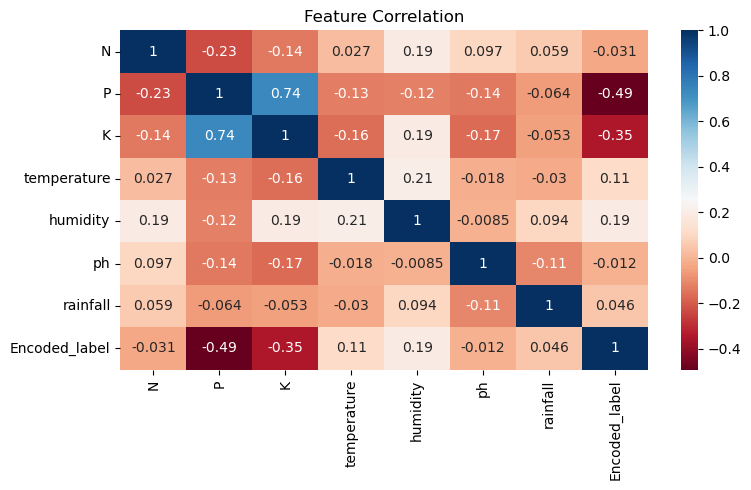

In [41]:
# ─── Cell 9: Correlation heatmap ──────────────────────────────────────────────
plt.figure(figsize=(8, 5))
sns.heatmap(data.corr(numeric_only=True), annot=True, cmap='RdBu')
plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

In [42]:
# ─── Cell 10: Train/test split ────────────────────────────────────────────────
from sklearn.model_selection import train_test_split

FEATURE_COLS = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
TARGET_COL   = 'Encoded_label'

# Validate columns exist before splitting
missing_cols = [c for c in FEATURE_COLS + [TARGET_COL] if c not in data.columns]
if missing_cols:
    raise ValueError(f"Missing expected columns: {missing_cols}")

X = data[FEATURE_COLS]
y = data[TARGET_COL]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (1760, 7) | Test: (440, 7)


✅ XGBoost accuracy: 0.9932


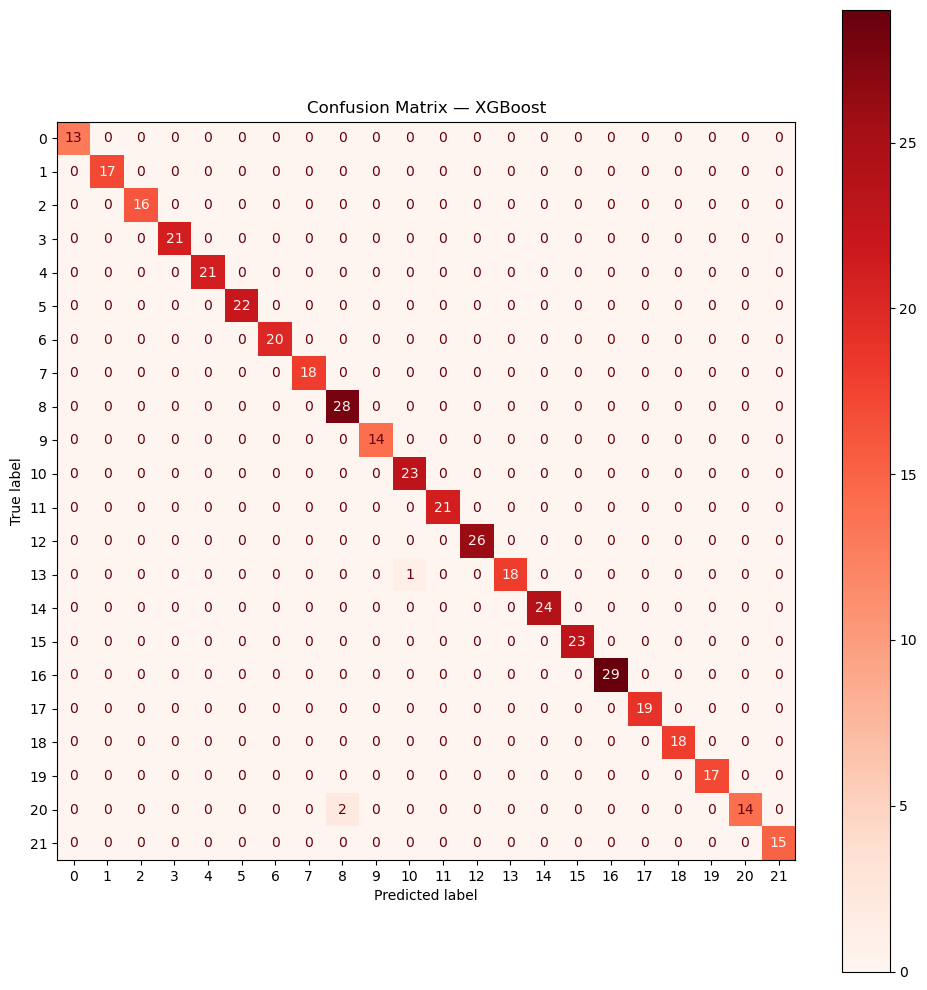


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        13
           1       1.00      1.00      1.00        17
           2       1.00      1.00      1.00        16
           3       1.00      1.00      1.00        21
           4       1.00      1.00      1.00        21
           5       1.00      1.00      1.00        22
           6       1.00      1.00      1.00        20
           7       1.00      1.00      1.00        18
           8       0.93      1.00      0.97        28
           9       1.00      1.00      1.00        14
          10       0.96      1.00      0.98        23
          11       1.00      1.00      1.00        21
          12       1.00      1.00      1.00        26
          13       1.00      0.95      0.97        19
          14       1.00      1.00      1.00        24
          15       1.00      1.00      1.00        23
          16       1.00      1.00      1.00        29
  

In [43]:
 # ─── Cell 11: XGBoost model ───────────────────────────────────────────────────
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay

try:
    xgb = XGBClassifier(random_state=42, eval_metric='mlogloss', verbosity=0)
    xgb.fit(X_train, y_train)
    pred_xgb = xgb.predict(X_test)
    acc_xgb  = accuracy_score(y_test, pred_xgb)
    print(f"✅ XGBoost accuracy: {acc_xgb:.4f}")
except Exception as e:
    raise RuntimeError(f"Model training failed: {e}")

# Confusion matrix (new API — plot_confusion_matrix was removed in sklearn 1.2)
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay.from_estimator(xgb, X_test, y_test, ax=ax, cmap='Reds')
plt.title("Confusion Matrix — XGBoost")
plt.tight_layout()
plt.show()

print("\nClassification Report:\n", classification_report(y_test, pred_xgb))

In [44]:
# ─── Cell 12: Save model ──────────────────────────────────────────────────────
MODEL_PATH = "classifier.pkl"

try:
    with open(MODEL_PATH, 'wb') as f:
        pickle.dump(xgb, f)
    print(f"✅ Model saved to {MODEL_PATH}")
except IOError as e:
    raise IOError(f"Could not save model: {e}")

✅ Model saved to classifier.pkl


In [45]:
# ─── Cell 13: Load model & predict ───────────────────────────────────────────
# Input to predict — [N, P, K, temperature, humidity, ph, rainfall]
sample = [[80, 35, 40, 30, 80, 7.5, 100]]

try:
    if not os.path.exists(MODEL_PATH):
        raise FileNotFoundError(f"Model file not found: {MODEL_PATH}. Run Cell 12 first.")

    with open(MODEL_PATH, 'rb') as f:
        model = pickle.load(f)

    # Validate input shape
    sample_arr = np.array(sample)
    if sample_arr.shape[1] != len(FEATURE_COLS):
        raise ValueError(
            f"Input must have {len(FEATURE_COLS)} features, got {sample_arr.shape[1]}"
        )

    proba = model.predict_proba(sample_arr)
    results = (
        pd.DataFrame(data=np.round(proba.T * 100, 2), index=classes.index, columns=['confidence_%'])
    )
    print("✅ Top 5 crop recommendations:")
    display(results.nlargest(5, 'confidence_%'))

except FileNotFoundError as e:
    print(f"❌ {e}")
except ValueError as e:
    print(f"❌ Input error: {e}")
except Exception as e:
    print(f"❌ Prediction failed: {e}")

✅ Top 5 crop recommendations:


,confidence_%
label,
jute,8.42
mango,7.67
coffee,6.52
banana,6.22
papaya,5.59


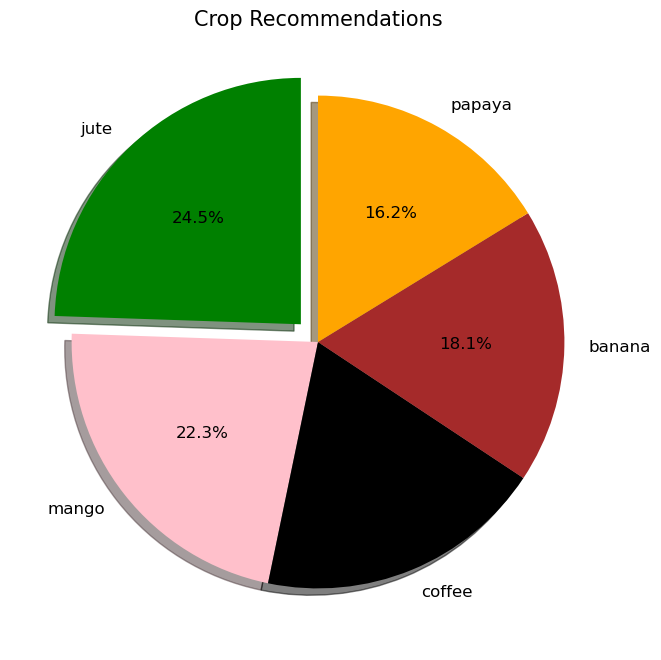

In [46]:
# ─── Cell 14: Plot recommendations ───────────────────────────────────────────
try:
    top5 = results['confidence_%'].nlargest(5)

    if top5.empty or top5.sum() == 0:
        print("⚠️  No significant predictions to display.")
    else:
        plt.figure(figsize=(10, 8))
        plt.rcParams['font.size'] = 12
        plt.title('Crop Recommendations', fontdict={'fontsize': 15, 'fontweight': 'medium'})
        plt.pie(
            x=top5,
            labels=top5.index,
            autopct='%1.1f%%',
            explode=[0.1] + [0] * (len(top5) - 1),
            shadow=True,
            startangle=90,
            colors=['green', 'pink', 'black', 'brown', 'orange']
        )
        plt.show()
except Exception as e:
    print(f"❌ Could not plot results: {e}")
